In [1]:
# 1)Given a character array, reverse the array in-place. Requirements: 
# 1.⁠ ⁠Provide an optimal solution in terms of space and time complexity. 
# 2.⁠ ⁠Don't use extra space. 3.⁠ ⁠Time Complexity should be O(n). 
# Example: Input: ["h", "e", "l", "l", "o"] Output: ["o", "l", "l", "e", "h"]
def reverse_array(arr):
    left = 0
    right = len(arr) - 1

    while left < right:
        arr[left], arr[right] = arr[right], arr[left]
        left += 1
        right -= 1

    return arr


# Example
arr = ["h", "e", "l", "l", "o"]

print(reverse_array(arr))

['o', 'l', 'l', 'e', 'h']


In [2]:
# 2) Write a function that merges two sorted integer arrays into a single sorted array. 
# The function should maintain sorted order and handle arrays of different lengths.
# Requirements:
# 1.⁠ ⁠Do not use built-in sorting methods.
# Example:
# Input: arr1 = [1, 3, 5], arr2 = [2, 4, 6]
# Output: [1, 2, 3, 4, 5, 6]

def merge_sorted_arrays(arr1, arr2):
    merged_array = []
    i, j = 0, 0

    while i < len(arr1) and j < len(arr2):
        if arr1[i] < arr2[j]:
            merged_array.append(arr1[i])
            i += 1
        else:
            merged_array.append(arr2[j])
            j += 1

    # Append remaining elements from arr1
    while i < len(arr1):
        merged_array.append(arr1[i])
        i += 1

    # Append remaining elements from arr2
    while j < len(arr2):
        merged_array.append(arr2[j])
        j += 1

    return merged_array
arr1 = [1, 3, 5]    
arr2 = [2, 4, 6]
print(merge_sorted_arrays(arr1, arr2))

[1, 2, 3, 4, 5, 6]


In [ ]:
# Return a new list that keeps only the first value from each consecutive run of equal values, preserving their order. Equal values separated by another value belong to different runs.

# Assume values is a non-empty list of integers.

# EXAMPLE INPUT: values=[4, 4, 4, 2, 2, 2, 4, 4, 4]
# EXAMPLE OUTPUT: result=[4, 2, 4]
def first_of_runs(values):
    result = [values[0]]          # always include first element

    for i in range(1, len(values)):
        if values[i] != values[i - 1]:   # new run starts
            result.append(values[i])

    return result

values = [4, 4, 4, 2, 2, 2, 4, 4, 4]
print(first_of_runs(values))   # [4, 2, 4]

In [3]:
# Return the number of positions, excluding the first, where the value 
# is strictly greater than the immediately preceding value. Equal 
# neighboring values do not count as an increase. Return 0 for a list containing one value.

# Assume values is a non-empty list of integers.

# EXAMPLE INPUT: values=[3, 5, 5, 7, 8, 2]
# EXAMPLE OUTPUT: count=3


def count_increases(values):
    count = 0
    for i in range(1, len(values)):
        if values[i] > values[i - 1]:
            count += 1
    return count

values = [3, 5, 5, 7, 8, 2]
print(count_increases(values))   # 3

3


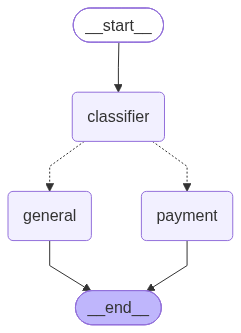

---
config:
  flowchart:
    curve: linear
---
graph TD;
	__start__([<p>__start__</p>]):::first
	classifier(classifier)
	payment(payment)
	general(general)
	__end__([<p>__end__</p>]):::last
	__start__ --> classifier;
	classifier -.-> general;
	classifier -.-> payment;
	general --> __end__;
	payment --> __end__;
	classDef default fill:#f2f0ff,line-height:1.2
	classDef first fill-opacity:0
	classDef last fill:#bfb6fc

          +-----------+            
          | __start__ |            
          +-----------+            
                *                  
                *                  
                *                  
          +------------+           
          | classifier |           
          +------------+           
          ...        ...           
         .              .          
       ..                ..        
+---------+           +---------+  
| general |           | payment |  
+---------+           +---------+  
          ***        ***           
    

In [6]:
# 1) You are given shuffled lines of a fully working LangGraph food delivery 
# chatbot workflow. Your task is to put these lines in the correct 
# order so that the code runs and implements the workflow described below.
# The workflow should:
# 1.⁠ ⁠Create a ⁠ StateGraph ⁠ for a food delivery support state object.
# 2.⁠ ⁠Register one classifier node and two handler nodes.
# 3.⁠ ⁠Start by classifying the user query.
# 4.⁠ ⁠Route the query to payment or general support.
# 5.⁠ ⁠End after the selected handler node runs.
# 6.⁠ ⁠Compile and invoke the graph.

from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END


# ─────────────────────────────────────────────
# 1. Define the State
# ─────────────────────────────────────────────
class SupportState(TypedDict):
    query: str
    category: str        # "payment" or "general"
    response: str


# ─────────────────────────────────────────────
# 2. Define Node Functions
# ─────────────────────────────────────────────

# Classifier node
def classify_query(state: SupportState) -> SupportState:
    query = state["query"].lower()

    if any(word in query for word in ["payment", "refund", "charge", "billing", "money"]):
        category = "payment"
    else:
        category = "general"

    return {"category": category}


# Payment handler node
def payment_support(state: SupportState) -> SupportState:
    return {"response": f"[Payment Support] Handling: '{state['query']}'"}


# General handler node
def general_support(state: SupportState) -> SupportState:
    return {"response": f"[General Support] Handling: '{state['query']}'"}


# ─────────────────────────────────────────────
# 3. Routing Function
# ─────────────────────────────────────────────
def route_query(state: SupportState) -> Literal["payment", "general"]:
    return state["category"]


# ─────────────────────────────────────────────
# 4. Build the Graph
# ─────────────────────────────────────────────
builder = StateGraph(SupportState)

# Register nodes
builder.add_node("classifier", classify_query)
builder.add_node("payment", payment_support)
builder.add_node("general", general_support)

# Entry point
builder.add_edge(START, "classifier")

# Conditional routing from classifier
builder.add_conditional_edges(
    "classifier",
    route_query,
    {
        "payment": "payment",
        "general": "general",
    }
)

# End after each handler
builder.add_edge("payment", END)
builder.add_edge("general", END)

# Compile
graph = builder.compile()

from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))
# Print Mermaid diagram (text)
print(graph.get_graph().draw_mermaid())

# Print ASCII diagram (terminal-friendly)
print(graph.get_graph().draw_ascii())


# Save as PNG (requires pygraphviz or grandalf)
# graph.get_graph().draw_mermaid_png(output_file_path="graph.png")

# ─────────────────────────────────────────────
# 5. Invoke
# ─────────────────────────────────────────────
if __name__ == "__main__":
    result1 = graph.invoke({"query": "I want a refund for my last order"})
    print(result1)

    result2 = graph.invoke({"query": "Where is my delivery?"})
    print(result2)

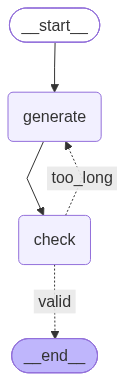

Final tweet: Generative AI is fascinating! Highly recommend exploring it. #GenerativeAI
Length: 74
Attempts: 2


In [15]:
# 2) You are given shuffled lines of a fully working LangGraph Twitter agent workflow. 
# Your task is to put these lines in the correct order so that the code runs and implements 
# the workflow described below.
# The workflow should:

# 1.⁠ ⁠Create a ⁠ StateGraph ⁠ for a tweet state object.
# 2.⁠ ⁠Register tweet generation and length checking nodes.
# 3.⁠ ⁠Start with tweet generation from a topic.
# 4.⁠ ⁠Check whether the tweet is short enough.
# 5.⁠ ⁠Retry tweet generation when the tweet is too long.
# 6.⁠ ⁠End when the tweet length is valid.
# 7.⁠ ⁠Compile and invoke the graph.

from typing import TypedDict
from langgraph.graph import StateGraph, START, END


# ─────────────────────────────────────────────
# 1. Define the State
# ─────────────────────────────────────────────
class TweetState(TypedDict):
    topic: str
    tweet: str
    length: int
    attempts: int


# ─────────────────────────────────────────────
# 2. Define Node Functions
# ─────────────────────────────────────────────
MAX_LENGTH = 100


def generate_tweet(state: TweetState) -> TweetState:
    """Generate a tweet from the topic. Shortens on each retry."""
    topic = state["topic"]
    attempts = state.get("attempts", 0)

    # Simulate generation — shorter each retry
    variants = [
        f"Just learned about {topic}! This is amazing and everyone should know about it. #learning #{topic.replace(' ', '')}",
        f"{topic} is fascinating! Highly recommend exploring it. #{topic.replace(' ', '')}",
        f"Exploring {topic} today. Mind blown! #{topic.replace(' ', '')}",
        f"{topic} rocks! #{topic.replace(' ', '')}",
        f"{topic}!",
    ]

    tweet = variants[min(attempts, len(variants) - 1)]

    return {
        "tweet": tweet,
        "length": len(tweet),
        "attempts": attempts + 1,
    }


def check_length(state: TweetState) -> TweetState:
    """Check if the tweet is short enough (no modification needed)."""
    return state


# ─────────────────────────────────────────────
# 3. Routing Function
# ─────────────────────────────────────────────
def is_valid_length(state: TweetState) -> str:
    if state["length"] <= MAX_LENGTH:
        return "valid"
    if state["attempts"] >= 5:
        return "valid"          # give up after 5 tries
    return "too_long"


# ─────────────────────────────────────────────
# 4. Build the Graph
# ─────────────────────────────────────────────
builder = StateGraph(TweetState)

# Register nodes
builder.add_node("generate", generate_tweet)
builder.add_node("check", check_length)

# Entry point
builder.add_edge(START, "generate")

# Generate → Check
builder.add_edge("generate", "check")

# Conditional: retry or end
builder.add_conditional_edges(
    "check",
    is_valid_length,
    {
        "too_long": "generate",   # loop back to regenerate
        "valid": END,             # done
    }
)

# Compile
graph = builder.compile()

from IPython.display import Image, display

display(Image(graph.get_graph().draw_mermaid_png()))

# ─────────────────────────────────────────────
# 5. Invoke
# ─────────────────────────────────────────────
if __name__ == "__main__":
    result = graph.invoke({"topic": "Generative AI", "attempts": 0})
    print("Final tweet:", result["tweet"])
    print("Length:", result["length"])
    print("Attempts:", result["attempts"])

In [7]:
def merge_sorted_arrays(arr1,arr2):
  merged_arry=[]
  i,j=0,0
  while i < len(arr1) and j  < len(arr2):
    if arr1[i] < arr2[j]:
      merged_arry.append(arr1[i])
      i+=1
    else:
      merged_arry.append(arr2[j])
      j+=1
  while i < len(arr1) :
    merged_arry.append(arr1[i])
    i+=1
  while j < len(arr2) :
    merged_arry.append(arr2[j])  
    j+=1
  return merged_arry  

arr1 = [1, 3, 5]    
arr2 = [2, 4, 6]
print(merge_sorted_arrays(arr1, arr2))

[1, 2, 3, 4, 5, 6]


In [ ]:
# Online Python compiler (interpreter)
# Write and run Python online using this editor.

print("What does the Visualize button do?")

arr1 = [1, 3, 5] 
arr2 = [2, 4, 6]
i=0
j=0
sortedArr=[]
while i < len(arr1) and j< len(arr2):
     if arr1[i] < arr2[j]:
       sortedArr.append(arr1[i])
       i +=1
     else:
       sortedArr.append(arr2[j])
       j +=1
while i < len(arr1):
      sortedArr.append(arr1[i])
      i +=1
while j <len(arr2):
      sortedArr.append(arr2[j])
      j +=1
print(sortedArr)
       




What does the Visualize button do?
[1, 2, 3, 4, 5]


In [2]:
### 2. O(log n) — Logarithmic Time

def binary_search(arr, target):
    low = 0
    high = len(arr) - 1

    while low <= high:
        mid = (low + high) // 2

        if arr[mid] == target:
            return mid          # found
        elif arr[mid] < target:
            low = mid + 1       # search right half
        else:
            high = mid - 1      # search left half

    return -1                   # not found

arr = [10, 20, 30, 40, 50, 60, 70, 80]

#arr = [10, 70, 30, 40, 50, 60, 50, 80]
print(binary_search(arr, 70))   # 6
# print(binary_search(arr, 25))   # -1 (not found)

6


In [3]:
arr = [10, 20, 30, 40, 50, 60, 70, 80]
target = 70

print(any(target == val for val in arr))   # True

True


In [ ]:
arr = [10, 20, 30, 40, 50, 60, 70, 80]
target = 70

matches = [i for i, val in enumerate(arr) if val == target]
print(matches)   # [6]

In [ ]:
arr = [10, 20, 30, 40, 50, 60, 70, 80]
target = 70

print(next((i for i, val in enumerate(arr) if val == target), -1))   # 6

Hi [Candidate Name],
As discussed, please focus your interview preparation on the following key areas:
High Priority Topics
•⁠  ⁠Agentic AI & Multi-Agent Architecture (LangGraph, MCP, Tool Calling, Memory, Orchestration)
•⁠  ⁠Advanced RAG Architecture (Chunking, Embeddings, Hybrid Search, Reranking, Evaluation)
•⁠  ⁠AI Evaluation & Observability
•⁠  ⁠CI/CD, MLOps & AI SDLC
•⁠  ⁠Python Coding & Problem Solving
•⁠  ⁠Classical Machine Learning Fundamentals
Additional Areas
•⁠  ⁠LLM & GenAI Fundamentals
•⁠  ⁠LangChain & LangGraph
•⁠  ⁠Security, RBAC & AI Governance
•⁠  ⁠AWS Bedrock, ECS/EKS, ECR, API Gateway
•⁠  ⁠Docker & Kubernetes Basics
•⁠  ⁠Enterprise AI Platforms (AgentBricks, AgentCore, Foundry, Snowflake Cortex)
Key Architecture Topics
Please be prepared to discuss:
•⁠  ⁠Multi-Agent AI Systems
•⁠  ⁠Enterprise RAG Solutions
•⁠  ⁠Security & Access Control
•⁠  ⁠Scalability & Reliability
•⁠  ⁠CI/CD and Deployment Strategies
•⁠  ⁠Monitoring, Evaluation, and Cost Optimization
Coding Preparation
Practice common Python problems such as:
•⁠  ⁠Removing duplicates while maintaining order
•⁠  ⁠String manipulation
•⁠  ⁠Character frequency
•⁠  ⁠First non-repeating character
•⁠  ⁠Two Sum
•⁠  ⁠Palindrome and Anagram problems
For architecture discussions, focus on explaining the complete lifecycle:
Business Requirement → Architecture → Model/RAG → Security → Evaluation → CI/CD → Deployment → Monitoring → Continuous Improvement
Based on previous feedback, your strengths are in GenAI, RAG, and Agentic AI. Please spend additional time strengthening Python coding, CI/CD/MLOps, and ML fundamentals.
Wishing you the very best for your interview preparation.
Regards,
